# Reconstruct a synthetic 3D sample

Generate a small volume and compare filtered backprojection (FBP) with
conjugate-gradient least squares (CGLS). The sample and projections are generated
in memory; no TomoPhantom installation or external dataset is needed.

**Requirements:** a CUDA-capable NVIDIA GPU, ASTRA with CUDA support, CuPy,
NumPy, Matplotlib and ToMoBAR. Run all cells in your GPU environment and save the notebook, including
its outputs. Documentation builds display those saved results without execution. Runtime and peak GPU memory have not
yet been measured; the default working volume is only 48 cubed voxels.

This example uses the same ASTRA model for projection and reconstruction. It
demonstrates the API and is not an independent benchmark of physical accuracy.

In [1]:
%matplotlib inline

import cupy as cp
import matplotlib.pyplot as plt
import numpy as np

from tomobar.geometry import Parallel3DGeometry, Volume3DGeometry
from tomobar.reconstruction.direct import RecToolsDIR
from tomobar.reconstruction.iterative import RecToolsIR

## Build the known sample
Voxel centres are symmetric about the volume origin. Arrays use (Z, Y, X).
Three ellipsoids with different attenuation values make orientation and
contrast changes visible. All lengths are in unit-voxel coordinates.

In [2]:
size = 48
view_count = 90
cgls_iterations = 20
device_index = 0
coordinates = np.arange(size, dtype=np.float32) - (size - 1) / 2
z, y, x = np.meshgrid(coordinates, coordinates, coordinates, indexing="ij")
phantom = np.zeros((size, size, size), dtype=np.float32)
phantom[(x / 15) ** 2 + (y / 12) ** 2 + (z / 16) ** 2 <= 1] = 0.5
phantom[((x - 7) / 5) ** 2 + ((y + 3) / 6) ** 2 + (z / 8) ** 2 <= 1] = 1.0
phantom[((x + 8) / 4) ** 2 + ((y - 4) / 4) ** 2 + ((z - 5) / 6) ** 2 <= 1] = 0.2

## Acquire a half-turn tomography scan
Exclude the repeated endpoint. Detector columns cover the sample diagonal;
rows cover the full volume height. Native projection axes are
(detector rows, views, detector columns), labelled (detY, angles, detX).

In [3]:
grid = Volume3DGeometry(shape=phantom.shape)
scan = Parallel3DGeometry.tomography(
    angles=np.linspace(0, np.pi, view_count, endpoint=False),
    detector_shape=(size, int(np.ceil(np.sqrt(2) * size))),
)

with RecToolsDIR(
    projection_geometry=scan, volume_geometry=grid, device_index=device_index
) as direct:
    projections = direct.forward(phantom)
    fbp = direct.FBP(projections, filter_type="RAM-LAK", recon_mask_radius=None)

print(f"Projection shape (detY, angles, detX): {projections.shape}")

Projection shape (detY, angles, detX): (48, 90, 68)


## Fit the same measurements with CGLS
CGLS starts from zeros and uses unfiltered line integrals. It returns a CuPy
array even when its input is NumPy; transfer the final image for plotting.
Twenty iterations are an illustrative budget, not a convergence guarantee.

In [4]:
with RecToolsIR(
    projection_geometry=scan,
    volume_geometry=grid,
    device_index=device_index,
    backend="astra",
) as iterative:
    cgls = cp.asnumpy(
        iterative.CGLS(projections, iterations=cgls_iterations, recon_mask_radius=None)
    )

for name, image in [("FBP", fbp), ("CGLS", cgls)]:
    rmse = np.sqrt(np.mean((image - phantom) ** 2))
    print(f"{name} RMSE over the full volume: {rmse:.5f}")

FBP RMSE over the full volume: 0.02131
CGLS RMSE over the full volume: 0.01444


## Compare slices on a common scale
The objects should retain their locations and relative attenuation values.
Sampling, discretisation and finite CGLS iteration count can leave differences
from the known volume, especially near sharp boundaries.

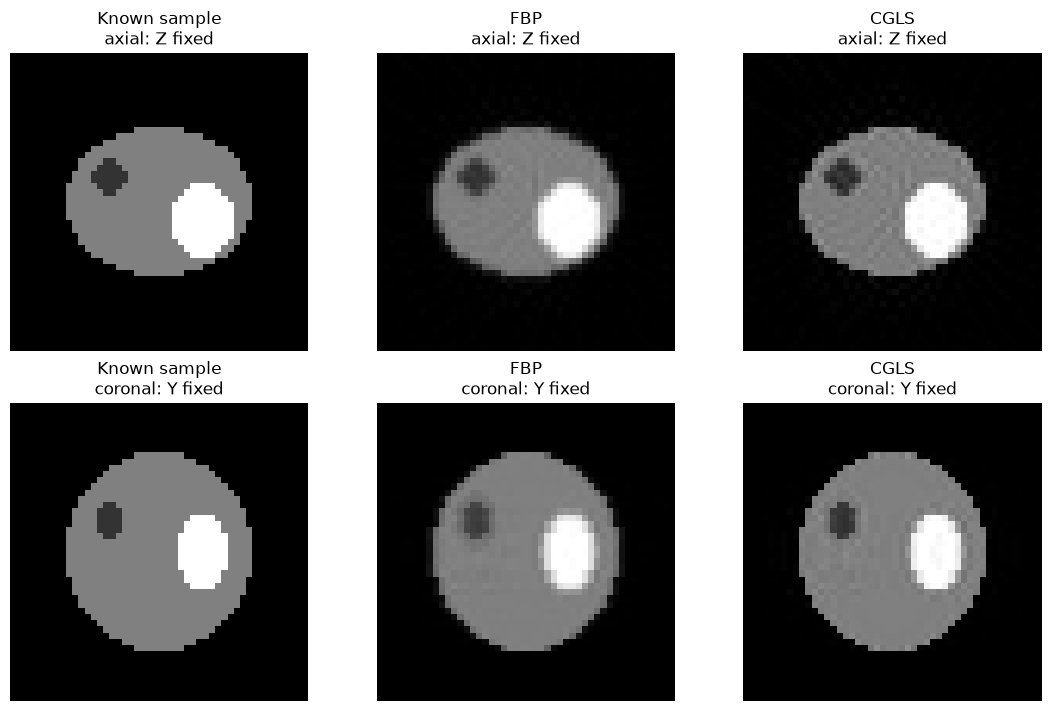

In [5]:
figure, axes = plt.subplots(2, 3, figsize=(11, 7), constrained_layout=True)
middle = size // 2
for column, (name, image) in enumerate(
    [("Known sample", phantom), ("FBP", fbp), ("CGLS", cgls)]
):
    for row, (label, section) in enumerate(
        [("axial: Z fixed", image[middle]), ("coronal: Y fixed", image[:, middle, :])]
    ):
        axes[row, column].imshow(section, origin="lower", cmap="gray", vmin=0, vmax=1)
        axes[row, column].set_title(f"{name}\n{label}")
        axes[row, column].set_axis_off()
plt.show()